# Before you start :
   - These exercises are related to the Pivot table and correlation lessons.
   - Keep in mind that you need to use some of the functions you learned in the previous lessons.
   - All datasets are provided in the `your-code` folder of this lab.
   - Elaborate your codes and outputs as much as you can.
   - Try your best to answer the questions and complete the tasks and most importantly enjoy the process!!!

#### Import all the libraries that are necessary

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
%matplotlib inline

# Challenge 1

#### Open the ` Employee.csv` file and name your dataset `employee`

In [3]:
employee = pd.read_csv("https://raw.githubusercontent.com/Dee-M123/lab-pivot-tables-and-correlations/refs/heads/main/your-code/data/Employee.csv")

employee.head()

,Name,Department,Education,Gender,Title,Years,Salary
0,Jose,IT,Bachelor,M,analyst,1,35
1,Maria,IT,Master,F,analyst,2,30
2,David,HR,Master,M,analyst,2,30
3,Sonia,HR,Bachelor,F,analyst,4,35
4,Samuel,Sales,Master,M,associate,3,55


#### What's the mean salary by department.
##### Tip : There are 2 ways to do it - one way is with and the other way is without pivot tables. Do it both ways.


In [4]:
mean_salary = employee.groupby("Department")["Salary"].mean()
print(mean_salary)

Department
HR       45.00
IT       48.75
Sales    55.00
Name: Salary, dtype: float64


In [5]:
pivot = employee.pivot_table(values="Salary", index="Department", aggfunc="mean")

print(pivot)

            Salary
Department        
HR           45.00
IT           48.75
Sales        55.00


#### We want now to group the data by more than one column. Use Pandas pivot table function to select the mean salary by department and title

In [7]:
pivot = employee.pivot_table(values="Salary",index=["Department", "Title"],aggfunc="mean")

print(pivot)

                      Salary
Department Title            
HR         VP           70.0
           analyst      32.5
IT         VP           70.0
           analyst      32.5
           associate    60.0
Sales      associate    55.0


#### We want to display the number of years of work experience and the salary for each Title. Add Years as a column in your pivot table
*Hint: Use Pandas doc(see References in README.md) to explore the pivot_table() arguments*

In [8]:
pivot = employee.pivot_table(index="Title",values=["Years", "Salary"],aggfunc="mean"
)

print(pivot)

              Salary  Years
Title                      
VP         70.000000   8.00
analyst    32.500000   2.25
associate  56.666667   4.00


#### We want to know the information about the mean salary and number of employees in each department and for each job title

In [10]:
pivot = employee.pivot_table(index=["Department", "Title"],values="Salary",aggfunc=["mean", "count"])

print(pivot)

                       mean  count
                     Salary Salary
Department Title                  
HR         VP          70.0      1
           analyst     32.5      2
IT         VP          70.0      1
           analyst     32.5      2
           associate   60.0      1
Sales      associate   55.0      2


#### We want to know for each department and for each job title the Salary's median,minimum,maximum and standard deviation. Comment your results

In [12]:
pivot = employee.pivot_table(index=["Department", "Title"],values="Salary",aggfunc=["median", "min", "max", "std"])

print(pivot)

                     median    min    max       std
                     Salary Salary Salary    Salary
Department Title                                   
HR         VP          70.0     70     70       NaN
           analyst     32.5     30     35  3.535534
IT         VP          70.0     70     70       NaN
           analyst     32.5     30     35  3.535534
           associate   60.0     60     60       NaN
Sales      associate   55.0     55     55  0.000000


#### Based on your comments, fill the missing values with an appropriate value

In [13]:
pivot = employee.pivot_table(index=["Department", "Title"],values="Salary",aggfunc=["median", "min", "max", "std"])

# Replace Null with 0
pivot = pivot.fillna(0)

print(pivot)

                     median    min    max       std
                     Salary Salary Salary    Salary
Department Title                                   
HR         VP          70.0     70     70  0.000000
           analyst     32.5     30     35  3.535534
IT         VP          70.0     70     70  0.000000
           analyst     32.5     30     35  3.535534
           associate   60.0     60     60  0.000000
Sales      associate   55.0     55     55  0.000000


#### The stake holders want to know for each department the number of employees and how much money is spend on salaries. Could you provide that information?

In [14]:
pivot = employee.pivot_table(index="Department",values="Salary",aggfunc=["count", "sum"])

pivot.columns = ["Employee Count", "Total Salary"]
pivot = pivot.reset_index()

print(pivot)

  Department  Employee Count  Total Salary
0         HR               3           135
1         IT               4           195
2      Sales               2           110


#### For each Department and Title, we want to know the the total years of work experience and the mean salary

In [15]:
pivot = employee.pivot_table(index=["Department", "Title"],values=["Years", "Salary"],aggfunc={"Years": "sum", "Salary": "mean"}
)

print(pivot)

                      Salary  Years
Department Title                   
HR         VP           70.0      8
           analyst      32.5      6
IT         VP           70.0      8
           analyst      32.5      3
           associate    60.0      7
Sales      associate    55.0      5


#### Bonus

#### We now want to compute the mean salary after removing the maxima for each Department. Create the appropriate pivot table

#### * Hint: Write a custom function*

In [ ]:
# your answer here--Your custom function here


In [ ]:
# your answer here

# Challenge 2

#### Open the ` Fitbit.csv` file and name your dataset `fitbit`

In [17]:
fitbit = pd.read_csv("https://raw.githubusercontent.com/Dee-M123/lab-pivot-tables-and-correlations/refs/heads/main/your-code/data/Fitbit.csv")

fitbit.head()

,Date,Calorie burned,Steps,Distance,Floors,Minutes Sedentary,Minutes Lightly Active,Minutes Fairly Active,Minutes Very Active,Activity Calories,MinutesOfSleep,MinutesOfBeingAwake,NumberOfAwakings,LengthOfRestInMinutes
0,08-05-2015,1934,905,0.65,0,1.355,46,0,0,1680,384,26,23,417
1,09-05-2015,3631,18925,14.11,4,611.000,316,61,60,2248,454,35,21,491
2,10-05-2015,3204,14228,10.57,1,602.000,226,14,77,1719,387,46,25,436
3,11-05-2015,2673,6756,5.02,8,749.000,190,23,4,9620,311,31,21,350
4,12-05-2015,2495,502,3.73,1,876.000,171,0,0,7360,407,65,44,491


#### Explore you dataset in terms of data types and descriptive statistics
#### *Hint: Use Pandas functions from previous lectures*

In [19]:
print(fitbit.describe().T)

                        count          mean          std      min       25%  \
Calorie burned          367.0   2741.501362   916.307036  179.000  2698.000   
Steps                   367.0  10121.588556  5594.836225    0.000  6730.500   
Distance                367.0      8.549128     3.409881    0.000     6.155   
Floors                  367.0     11.724796    10.337370    0.000     5.000   
Minutes Sedentary       367.0    563.934482   294.793145    1.002   520.000   
Minutes Lightly Active  367.0    236.405995    86.531376    0.000   179.000   
Minutes Fairly Active   367.0     26.163488    20.319456    0.000     8.000   
Minutes Very Active     367.0     35.722071    31.006682    0.000    10.500   
Activity Calories       367.0   2044.147139  2041.267168    0.000  1218.500   
MinutesOfSleep          367.0    290.479564   154.752328    0.000   224.000   
MinutesOfBeingAwake     367.0     28.008174    18.541415    0.000    14.000   
NumberOfAwakings        367.0     16.196185    10.75

In [20]:
print(fitbit.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 367 entries, 0 to 366
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Date                    367 non-null    object 
 1   Calorie burned          367 non-null    int64  
 2   Steps                   367 non-null    int64  
 3   Distance                367 non-null    float64
 4   Floors                  367 non-null    int64  
 5   Minutes Sedentary       367 non-null    float64
 6   Minutes Lightly Active  367 non-null    int64  
 7   Minutes Fairly Active   367 non-null    int64  
 8   Minutes Very Active     367 non-null    int64  
 9   Activity Calories       367 non-null    int64  
 10  MinutesOfSleep          367 non-null    int64  
 11  MinutesOfBeingAwake     367 non-null    int64  
 12  NumberOfAwakings        367 non-null    int64  
 13  LengthOfRestInMinutes   367 non-null    int64  
dtypes: float64(2), int64(11), object(1)
memory

#### You suspect that there must be a linear relationship between the Minutes Very Active and the Steps. Compute the correlation between these variables.

In [21]:
correlation = fitbit["Steps"].corr(fitbit["Minutes Very Active"])

print(correlation)

0.5714518481062608


#### Use matplotlib to visually plot Minutes Very active vs Steps.

##### Hint : import matplotlib.pyplot as plt (See previous lessons)#####
- Use plt.scatter(x=df['col_name_1'], y=df['col_name_2'])

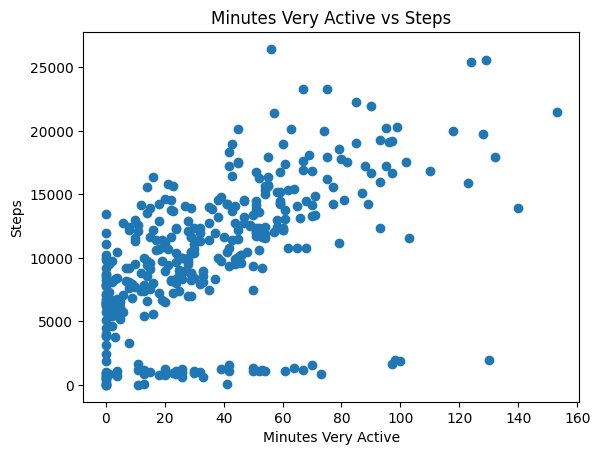

In [23]:
plt.figure()
plt.scatter(x=fitbit["Minutes Very Active"], y=fitbit["Steps"])

plt.xlabel("Minutes Very Active")
plt.ylabel("Steps")
plt.title("Minutes Very Active vs Steps")

plt.show()

#### What can you say about Minute Very Active and Steps? Write a comment below

In [ ]:
# There is a strong positive relationship between Minutes Very Active and Steps.

#### We also suspect that there must be a linear relationship between the Minutes Sedentary and the Steps. Compute the correlation between these variables.

In [24]:
correlation = fitbit["Steps"].corr(fitbit["Minutes Sedentary"])

print(correlation)

0.07690608062990091


#### Use matplotlib to visually plot Minutes Sedentary vs Steps. Based on the results of the computed correlation and the plot. What can you say about these 2 variables?

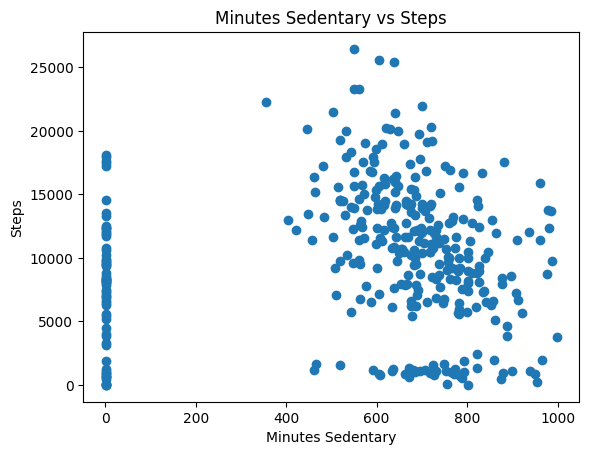

In [25]:
plt.figure()
plt.scatter(fitbit["Minutes Sedentary"], fitbit["Steps"])

# Labels and title
plt.xlabel("Minutes Sedentary")
plt.ylabel("Steps")
plt.title("Minutes Sedentary vs Steps")

plt.show()

In [ ]:
# No clear strong linear pattern

#### We also suspect that there must be a linear relationship between the MinutesOfSleep and the Steps. Compute the correlation between these variables.

In [26]:
corr_sleep_steps = fitbit["MinutesOfSleep"].corr(fitbit["Steps"])

corr_sleep_steps

np.float64(0.1309856595083638)

#### Use matplotlib to visually plot MinutesOfSleep vs Steps. Based on the results of the computed correlation and the plot. What can you say about these 2 variables?

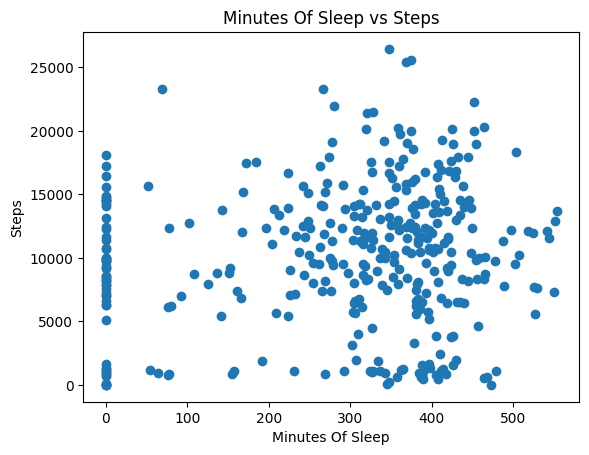

In [28]:
plt.figure()
plt.scatter(fitbit["MinutesOfSleep"], fitbit["Steps"])

# Labels and title
plt.xlabel("Minutes Of Sleep")
plt.ylabel("Steps")
plt.title("Minutes Of Sleep vs Steps")

plt.show()

In [ ]:
#no meaningful linear relationship

#### Select a subset of your dataset with the columns below and compute the correlation matrix. Save the results in the variable `cor_fit`
column= ['Calorie burned', 'Steps','Floors','Minutes Sedentary','Minutes Very Active', 'MinutesOfSleep']

In [29]:
columns = ['Calorie burned', 'Steps','Floors',
           'Minutes Sedentary','Minutes Very Active', 'MinutesOfSleep']

subset = fitbit[columns]

# Compute correlation
cor_fit = subset.corr()

cor_fit

,Calorie burned,Steps,Floors,Minutes Sedentary,Minutes Very Active,MinutesOfSleep
Calorie burned,1.000000,0.255305,0.130757,0.125353,0.197881,0.011485
Steps,0.255305,1.000000,0.306511,0.076906,0.571452,0.130986
Floors,0.130757,0.306511,1.000000,0.057812,0.399503,0.069464
Minutes Sedentary,0.125353,0.076906,0.057812,1.000000,0.105963,0.204242
Minutes Very Active,0.197881,0.571452,0.399503,0.105963,1.000000,0.108018
MinutesOfSleep,0.011485,0.130986,0.069464,0.204242,0.108018,1.000000


In [ ]:
# Minutes Very Active

#### Based on the result of the correlation matrix. What are the highly correlated features with the variable Steps?
*Hint: From the results above select the variable Steps and order your results in descending order (use Pandas sort_values function)*

In [ ]:
# Minutes Very Active

# Challenge 3

#### Open the `Time_Grades.csv` file and name your dataset `time_grades`

In [32]:
time_grades = pd.read_csv("http://raw.githubusercontent.com/Dee-M123/lab-pivot-tables-and-correlations/refs/heads/main/your-code/data/Time_Grades.csv")

time_grades

,Name,Study time,Grade
0,Jose,4,4
1,Maria,9,7
2,David,8,9
3,Sonia,10,7
4,Samuel,20,9
5,Eva,5,3
6,Carlos,12,7
7,Pedro,6,5
8,Ana,18,9
9,Gervasio,7,3


In [ ]:
#Print time_grades

#### Show visually the frequency distribution of the time_grades dataset.

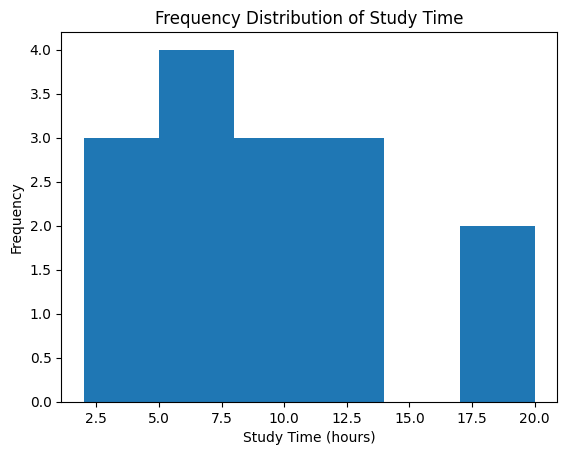

In [33]:
plt.figure()
plt.hist(time_grades["Study time"], bins=6)

plt.xlabel("Study Time (hours)")
plt.ylabel("Frequency")
plt.title("Frequency Distribution of Study Time")

plt.show()

#### Is there a correaltion between study time and Grade? Use both Pearson and Spearman correlation and comment your results.

In [35]:
pearson_corr = time_grades["Study time"].corr(time_grades["Grade"])

print(pearson_corr)

0.7980456073578858


In [40]:
from scipy.stats import spearmanr

spearman_corr, p_value = spearmanr(time_grades["Study time"],
                                   time_grades["Grade"])

spearman_corr, p_value

(np.float64(0.819658753036942), np.float64(0.00018377469445788485))

#### Use matplotlib to visually plot Study time vs Grade. Based on the results of the computed correlation and the plot. What can you say about these 2 variables?

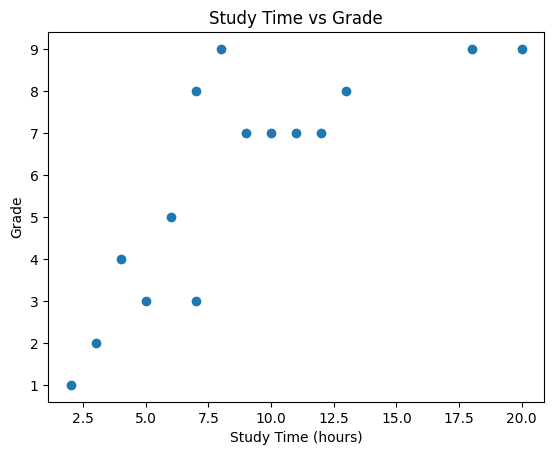

In [41]:
plt.figure()
plt.scatter(time_grades["Study time"], time_grades["Grade"])

plt.xlabel("Study Time (hours)")
plt.ylabel("Grade")
plt.title("Study Time vs Grade")

plt.show()

In [ ]:
#your comment here

#### Could you explain the difference between Pearson and Spearman correlation? (see References in README.md)

In [ ]:
# Pearson measures the strength of a linear relationship using actual values, while Spearman measures the strength of a monotonic relationship using ranked values.